[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChristofherdoVP/stokes-solar/blob/main/notebooks/01_stokes_mueller_polarimetro.ipynb)

# Notebook 01 — Parâmetros de Stokes, matrizes de Mueller e o polarímetro

Acompanha as Seções 2 e 3 do artigo. Gera a Figura 1 do artigo e as Figuras S1, S2 e S3 do material suplementar.

Convenções: $\delta = \phi_y - \phi_x$; $V > 0$ para rotação anti-horária vista pelo observador (IAU).

In [1]:
# Executa também no Google Colab: clona o repositório se necessário
import sys, os, subprocess
if 'google.colab' in sys.modules and not os.path.exists('stokes-solar'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/ChristofherdoVP/stokes-solar.git'], check=True)
    os.chdir('stokes-solar/notebooks')

In [2]:
import sys; sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch, FancyBboxPatch, Arc
import stokespy as sp
from stokespy.estilo import setup, virgula, salvar, CORES, COLUNA
setup()

## 1. Testes rápidos da Seção 2

Luz natural passando por um polarizador horizontal e por uma lâmina $\lambda/4$ com eixo rápido a $+45^\circ$ (exemplo resolvido da Seção 2.2).

In [3]:
S0 = np.array([1.0, 0, 0, 0])
S1 = sp.mueller_polarizer(0) @ S0
S2 = sp.mueller_retarder(np.pi/4, np.pi/2) @ S1
print('S1 =', S1, '  p =', sp.degree_of_polarization(S1)[0])
print('S2 =', np.round(S2, 12), ' -> V = -I: circular horária')
S2b = sp.mueller_retarder(-np.pi/4, np.pi/2) @ S1
print('eixo rápido a -45°:', np.round(S2b, 12))

S1 = [0.5 0.5 0.  0. ]   p = 1.0
S2 = [ 0.5  0.   0.  -0.5]  -> V = -I: circular horária
eixo rápido a -45°: [ 0.5  0.  -0.   0.5]


Conferência independente: soma direta dos campos. Uma onda com $\delta = +\pi/2$ deve girar no sentido anti-horário e ter $V > 0$.

In [4]:
t = np.linspace(0, 2*np.pi, 5)[:-1]
Ex, Ey = np.cos(t), np.cos(t - np.pi/2)
print('trajetória (Ex, Ey):', np.round(np.c_[Ex, Ey], 2).tolist(), '-> de x para y: anti-horário')
print('Stokes:', sp.stokes_from_field(1, 1, np.pi/2))

trajetória (Ex, Ey): [[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [-0.0, -1.0]] -> de x para y: anti-horário
Stokes: [2.0000000e+00 0.0000000e+00 1.2246468e-16 2.0000000e+00]


## 2. Figura S1 — Elipse de polarização

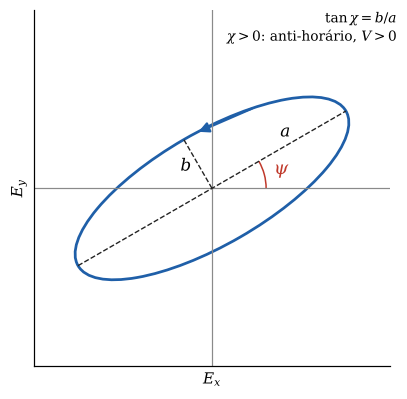

In [5]:
psi, chi = np.deg2rad(30), np.deg2rad(20)
A = 1.0; B = A*np.tan(chi)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.axhline(0, color=CORES['cinza'], lw=0.8); ax.axvline(0, color=CORES['cinza'], lw=0.8)
ax.add_patch(Ellipse((0, 0), 2*A, 2*B, angle=np.rad2deg(psi), fill=False, lw=1.8, color=CORES['Q']))
u = np.array([np.cos(psi), np.sin(psi)]); w = np.array([-np.sin(psi), np.cos(psi)])
ax.plot([-A*u[0], A*u[0]], [-A*u[1], A*u[1]], '--', color=CORES['I'], lw=0.9)
ax.plot([0, B*w[0]], [0, B*w[1]], '--', color=CORES['I'], lw=0.9)
ax.text(*(0.55*A*u + 0.07*w), '$a$', fontsize=11)
ax.text(*(0.55*B*w - 0.12*u), '$b$', fontsize=11)
ax.add_patch(Arc((0, 0), 0.7, 0.7, theta1=0, theta2=np.rad2deg(psi), color=CORES['V']))
ax.text(0.40, 0.09, '$\\psi$', color=CORES['V'], fontsize=12)
# sentido de rotação (chi > 0 => V > 0 => anti-horário)
ang = psi + np.deg2rad(60); p0 = A*np.cos(np.deg2rad(60))*u + B*np.sin(np.deg2rad(60))*w
p1 = A*np.cos(np.deg2rad(85))*u + B*np.sin(np.deg2rad(85))*w
ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=14, color=CORES['Q'], lw=1.5))
ax.text(1.02, 1.0, '$\\tan\\chi = b/a$\n$\\chi > 0$: anti-horário, $V > 0$', fontsize=9, ha='right', va='top', transform=ax.transAxes)
ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect('equal')
ax.set_xlabel('$E_x$'); ax.set_ylabel('$E_y$'); ax.set_xticks([]); ax.set_yticks([])
salvar(fig, 'figS1_elipse')

## 3. Figura S2 — Esfera de Poincaré (material suplementar)

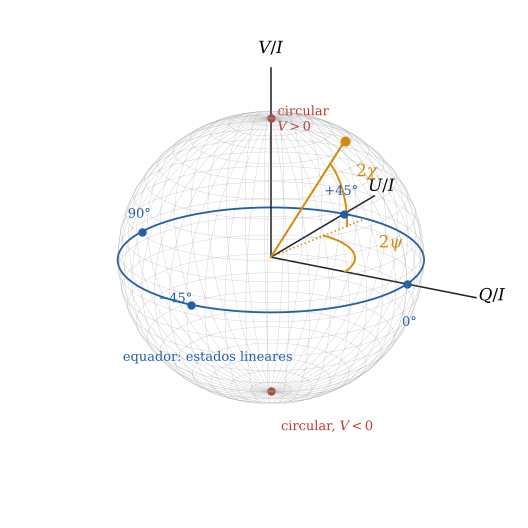

In [6]:
fig = plt.figure(figsize=(4.8, 4.6))
ax = fig.add_subplot(projection='3d')
uu, vv = np.mgrid[0:2*np.pi:48j, 0:np.pi:24j]
ax.plot_wireframe(np.cos(uu)*np.sin(vv), np.sin(uu)*np.sin(vv), np.cos(vv), color=CORES['cinza'], lw=0.25, alpha=0.45)
th = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(th), np.sin(th), 0, color=CORES['Q'], lw=1.2)
for v, lab in [((1.6,0,0),'$Q/I$'), ((0,1.55,0),'$U/I$'), ((0,0,1.45),'$V/I$')]:
    ax.plot([0, v[0]*0.93], [0, v[1]*0.93], [0, v[2]*0.93], color=CORES['I'], lw=1); ax.text(*v, lab, fontsize=11, ha='center')
pts = [((1,0,0), '0°', (0.15, -0.25, -0.18)), ((-1,0,0), '90°', (-0.05, 0.05, 0.08)),
       ((0,1,0), '+45°', (-0.05, 0.05, 0.12)), ((0,-1,0), '−45°', (0.0, -0.18, 0.08))]
for p, lab, d in pts:
    ax.scatter(*p, color=CORES['Q'], s=20, depthshade=False)
    ax.text(p[0]+d[0], p[1]+d[1], p[2]+d[2], lab, fontsize=8.5, color=CORES['Q'], ha='center')
ax.scatter(0, 0, 1, color=CORES['V'], s=20, depthshade=False); ax.scatter(0, 0, -1, color=CORES['V'], s=20, depthshade=False)
ax.text(0.25, -0.35, 1.05, 'circular\n$V > 0$', fontsize=8.5, color=CORES['V'])
ax.text(0.25, -0.3, -1.12, 'circular, $V < 0$', fontsize=8.5, color=CORES['V'])
ax.text(-0.35, -1.25, -0.38, 'equador: estados lineares', fontsize=8.5, color=CORES['Q'])
psi, chi = np.deg2rad(40), np.deg2rad(20)
P = sp.stokes_from_ellipse(psi, chi)[1:]
ax.scatter(*P, color=CORES['destaque'], s=30, depthshade=False)
ax.plot([0, P[0]], [0, P[1]], [0, P[2]], color=CORES['destaque'], lw=1.3)
ax.plot([0, np.cos(2*psi)], [0, np.sin(2*psi)], [0, 0], ':', color=CORES['destaque'], lw=1)
a2 = np.linspace(0, 2*psi, 40); ax.plot(0.55*np.cos(a2), 0.55*np.sin(a2), 0, color=CORES['destaque'], lw=1.2)
ax.text(0.72*np.cos(psi), 0.72*np.sin(psi), 0.02, '$2\\psi$', fontsize=11, color=CORES['destaque'])
b2 = np.linspace(0, 2*chi, 30); r = 0.8
ax.plot(r*np.cos(b2)*np.cos(2*psi), r*np.cos(b2)*np.sin(2*psi), r*np.sin(b2), color=CORES['destaque'], lw=1.2)
ax.text(0.95*np.cos(chi)*np.cos(2*psi), 0.95*np.cos(chi)*np.sin(2*psi), 0.95*np.sin(chi)+0.02, '$2\\chi$', fontsize=11, color=CORES['destaque'])
ax.set_box_aspect((1,1,0.95)); ax.set_axis_off(); ax.view_init(elev=20, azim=-60)
ax.set_xlim(-1,1); ax.set_ylim(-1,1); ax.set_zlim(-1,1)
fig.subplots_adjust(0, 0, 1, 1)
salvar(fig, 'figS2_poincare')

## 4. Figura S3 — Esquema de um polarímetro (material suplementar)

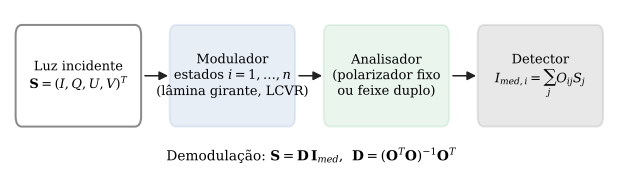

In [7]:
fig, ax = plt.subplots(figsize=(7.0, 2.0))
caixas = [(0.0, 'Luz incidente\n$\\mathbf{S} = (I, Q, U, V)^T$', 'none'),
          (2.0, 'Modulador\nestados $i = 1, \\ldots, n$\n(lâmina girante, LCVR)', CORES['Q']),
          (4.0, 'Analisador\n(polarizador fixo\nou feixe duplo)', CORES['U']),
          (6.0, 'Detector\n$I_{med,i} = \\sum_j O_{ij} S_j$', CORES['I'])]
for x, txt, col in caixas:
    ax.add_patch(FancyBboxPatch((x, 0.15), 1.55, 0.7, boxstyle='round,pad=0.04,rounding_size=0.08',
                                fc='white' if col == 'none' else col, alpha=1 if col == 'none' else 0.10,
                                ec=CORES['cinza'] if col == 'none' else col, lw=1.3))
    ax.text(x + 0.775, 0.5, txt, ha='center', va='center', fontsize=8.5)
for x in (1.6, 3.6, 5.6):
    ax.add_patch(FancyArrowPatch((x, 0.5), (x + 0.38, 0.5), arrowstyle='-|>', mutation_scale=12, color=CORES['I']))
ax.text(3.8, -0.15, 'Demodulação: $\\mathbf{S} = \\mathbf{D}\\,\\mathbf{I}_{med}$,  $\\mathbf{D} = (\\mathbf{O}^T\\mathbf{O})^{-1}\\mathbf{O}^T$',
        ha='center', fontsize=9)
ax.set_xlim(-0.1, 7.65); ax.set_ylim(-0.3, 1.0); ax.axis('off')
salvar(fig, 'figS3_polarimetro')

## 5. Modulação por lâmina girante e eficiências

Com lâmina de retardo $\Delta$ e polarizador horizontal fixo, cada linha de $\mathbf{O}$ é a primeira linha de $\mathbf{M}_{pol}(0)\,\mathbf{M}_{ret}(\theta_i, \Delta)$. Para $\Delta = \pi/2$:
$I_i = \tfrac{1}{2}(I + c_i^2 Q + c_i s_i U + s_i V)$.

In [8]:
theta = np.deg2rad(10); print(2*(sp.mueller_polarizer(0) @ sp.mueller_retarder(theta, np.pi/2))[0])
c2, s2 = np.cos(2*theta), np.sin(2*theta); print([1, c2**2, c2*s2, s2])

[1.         0.88302222 0.3213938  0.34202014]
[1, np.float64(0.8830222215594891), np.float64(0.3213938048432697), np.float64(0.3420201433256687)]


Arranjo ótimo da Seção 3: retardo $\approx 132^\circ$, eixos em $\pm 15{,}1^\circ$ e $\pm 51{,}7^\circ$. Busca numérica do ótimo:

In [9]:
from scipy.optimize import minimize
def neg_min_eff(p):
    D, a1, a2 = p
    return -sp.efficiency(sp.modulation_matrix([a1, -a1, a2, -a2], D))[1:].min()
r = minimize(neg_min_eff, np.deg2rad([125, 18, 48]), method='Nelder-Mead', options={'xatol': 1e-9, 'fatol': 1e-12})
D_opt, a1, a2 = r.x
print(f'retardo = {np.rad2deg(D_opt):.2f}°, ângulos = ±{np.rad2deg(a1):.2f}°, ±{np.rad2deg(a2):.2f}°')
print('eficiências (I, Q, U, V):', np.round(sp.efficiency(sp.modulation_matrix([a1, -a1, a2, -a2], D_opt)), 4), ' 1/√3 =', round(1/np.sqrt(3), 4))

retardo = 131.81°, ângulos = ±15.12°, ±51.69°
eficiências (I, Q, U, V): [1.     0.5774 0.5774 0.5774]  1/√3 = 0.5774


Verificação de Monte Carlo da relação $\sigma_j = \sigma/(\sqrt{n}\,\varepsilon_j)$:

In [10]:
O = sp.modulation_matrix([a1, -a1, a2, -a2], D_opt); Dm = sp.demodulation_matrix(O)
S_true = np.array([1, 0.01, -0.005, 0.02]); N = 1e6; n = 4
rec = np.array([Dm @ sp.simulate_measurements(S_true, O, N, rng=k) for k in range(20000)])
sigma = np.sqrt((O @ S_true).mean() / N)  # ruído de Poisson por exposição (aprox.)
print('desvio medido   :', np.round(rec.std(0)[1:], 6))
print('previsto σ/(√n ε):', np.round(sigma / (np.sqrt(n) * sp.efficiency(O)[1:]), 6))

desvio medido   : [0.000866 0.000863 0.00086 ]
previsto σ/(√n ε): [0.000866 0.000866 0.000866]


## 6. Figura 1 do artigo — assinaturas de modulação e eficiência em função do retardo

<>:18: SyntaxWarning: invalid escape sequence '\D'
<>:18: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_330/1592493054.py:18: SyntaxWarning: invalid escape sequence '\D'
  axb.set_xlabel('retardo $\Delta$ (graus)'); axb.set_ylabel('eficiência'); axb.set_ylim(0, 1); axb.set_xlim(60, 175)


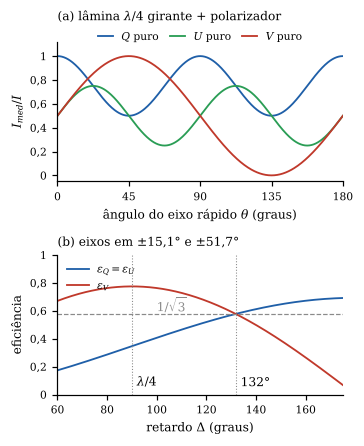

In [11]:
setup(base=8)
fig, (axa, axb) = plt.subplots(2, 1, figsize=(COLUNA, 4.1))
th = np.linspace(0, np.pi, 400)
for k, (lab, col) in enumerate([('$Q$', CORES['Q']), ('$U$', CORES['U']), ('$V$', CORES['V'])], start=1):
    S = np.zeros(4); S[0] = 1; S[k] = 1
    axa.plot(np.rad2deg(th), sp.modulation_matrix(th, np.pi/2) @ S / 2, color=col, label=lab + ' puro')
axa.set_xlabel('ângulo do eixo rápido $\\theta$ (graus)'); axa.set_ylabel('$I_{med}/I$')
axa.set_xticks([0, 45, 90, 135, 180]); axa.set_xlim(0, 180); axa.set_ylim(-0.05, 1.12)
axa.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.14), handlelength=1.4, columnspacing=1.0)
axa.set_title('(a) lâmina $\\lambda/4$ girante + polarizador', loc='left', pad=14); virgula(axa, 'y')
Ds = np.deg2rad(np.linspace(60, 175, 400))
E = np.array([sp.efficiency(sp.modulation_matrix([a1, -a1, a2, -a2], d)) for d in Ds])
axb.plot(np.rad2deg(Ds), E[:, 1], color=CORES['Q'], label='$\\varepsilon_Q = \\varepsilon_U$')
axb.plot(np.rad2deg(Ds), E[:, 3], color=CORES['V'], label='$\\varepsilon_V$')
axb.axhline(1/np.sqrt(3), color=CORES['cinza'], ls='--', lw=0.8)
axb.axvline(np.rad2deg(D_opt), color=CORES['cinza'], lw=0.7, ls=':'); axb.axvline(90, color=CORES['cinza'], lw=0.7, ls=':')
axb.text(np.rad2deg(D_opt) + 2, 0.06, f'{np.rad2deg(D_opt):.0f}°'); axb.text(92, 0.06, '$\\lambda/4$'); axb.text(100, 0.595, '$1/\\sqrt{3}$', color=CORES['cinza'])
axb.set_xlabel('retardo $\Delta$ (graus)'); axb.set_ylabel('eficiência'); axb.set_ylim(0, 1); axb.set_xlim(60, 175)
axb.legend(frameon=False, loc='upper left'); axb.set_title('(b) eixos em ±15,1° e ±51,7°', loc='left')
virgula(axb, 'y'); fig.tight_layout(h_pad=1.2)
salvar(fig, 'fig1_modulacao')
setup()

## Exercícios

1. Repita a busca do ótimo restringindo $\Delta = \pi/2$. Qual a menor eficiência que se consegue com quatro estados?
2. Use oito estados igualmente espaçados para uma lâmina $\lambda/4$. As eficiências melhoram?
3. Simule *seeing*: multiplique cada medida por $1 + \epsilon_i$ com $\epsilon_i$ aleatório de 1% e veja o vazamento de $I$ para $Q$, $U$ e $V$.